# COURSERA - TT2 Assignment
## Bird Species Classification with Transfer Learning

**Student Name:** Vivan Manish Shah  
**Roll Number:** C211  
**SAP ID:** 60004230030  
**Class / Division:** C3-2

### Aim
Train and evaluate a 10-species bird classifier, first documenting the original custom CNN baseline and then measuring whether ImageNet transfer learning improves generalization.

### Why the original result was 68.08%
The saved test result is **177/260 = 68.08%**. The original network had about 1.44 million parameters initialized from scratch, only 1,186 training images (about 100-133 per class), and a fixed 12-epoch budget. Its final training accuracy was 68.72%, with validation accuracy 72.16% at epoch 12; this points to limited learned features/undertraining rather than a large train/test generalization gap. The training script selected the minimum validation-loss checkpoint (epoch 11), which is a legitimate selection rule but does not necessarily maximize accuracy. The stored test result is kept as the baseline; the test set must not guide training choices.

This notebook keeps the original report and results as historical baseline material, then adds a reproducible pretrained ResNet-18 fine-tuning experiment.


In [ ]:

import os
import sys
import time
import json
import random
from pathlib import Path
from PIL import Image

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
import torchvision
from torchvision import transforms

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 70)
print("EXECUTION ENVIRONMENT & LIBRARY SPECIFICATIONS")
print("=" * 70)
print(f"Python Version:        {sys.version.split()[0]}")
print(f"PyTorch Version:       {torch.__version__}")
print(f"Torchvision Version:   {torchvision.__version__}")
print(f"NumPy Version:         {np.__version__}")
print(f"Pandas Version:        {pd.__version__}")
print(f"Matplotlib Version:    {plt.matplotlib.__version__}")
print(f"Seaborn Version:       {sns.__version__}")
print(f"Active Compute Device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU Execution'})")
print(f"Project Root:          {PROJECT_ROOT}")
print("=" * 70)


EXECUTION ENVIRONMENT & LIBRARY SPECIFICATIONS
Python Version:        3.12.10
PyTorch Version:       2.14.1+cpu
Torchvision Version:   0.29.1+cpu
NumPy Version:         1.26.4
Pandas Version:        2.2.2
Matplotlib Version:    3.9.1
Seaborn Version:       0.13.2
Active Compute Device: cpu (CPU Execution)
Project Root:          c:\Users\vivan\.gemini\antigravity-ide\scratch\bird-species-classifier


Total Dataset Images:           1701
Train Partition Images:         1186
Validation Partition Images:    255
Test Partition Images:          260
SHA-256 Unique Hashes:          1701
Cross-Split Content Duplicates: 0 (Zero Data Leakage)


,Class Index,Species Name,Train (70%),Val (15%),Test (15%),Total Images
0,0,ABBOTTS BABBLER,121,26,26,173
1,1,ABBOTTS BOOBY,133,28,29,190
2,2,ABYSSINIAN GROUND HORNBILL,132,28,29,189
3,3,AFRICAN CROWNED CRANE,101,22,22,145
4,4,AFRICAN EMERALD CUCKOO,114,25,25,164
5,5,AFRICAN FIREFINCH,102,22,23,147
6,6,AFRICAN OYSTER CATCHER,115,25,25,165
7,7,AFRICAN PIED HORNBILL,137,30,30,197
8,8,AFRICAN PYGMY GOOSE,132,28,29,189
9,9,ALBATROSS,99,21,22,142


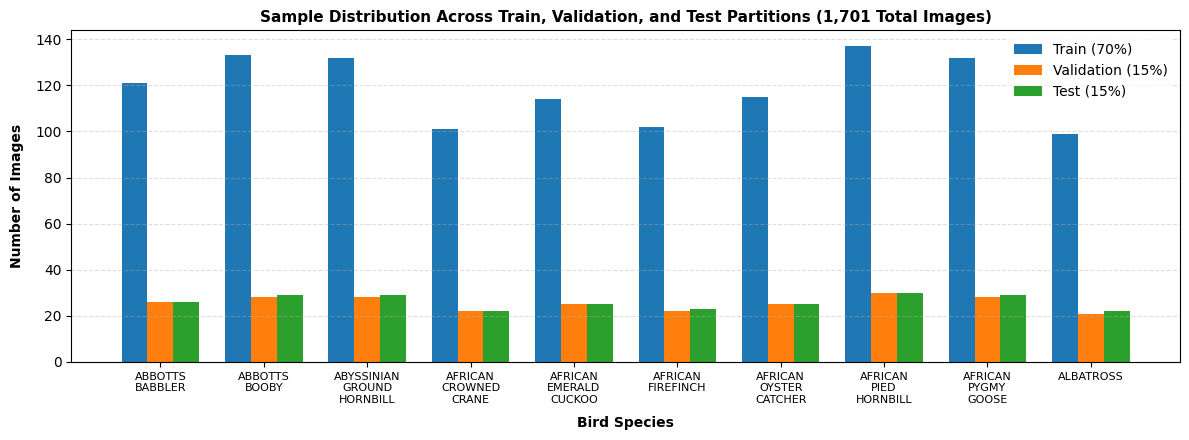

In [ ]:

metadata_path = PROJECT_ROOT / "data" / "metadata.json"
with open(metadata_path, "r") as f:
    metadata = json.load(f)

classes = metadata.get("selected_species", metadata.get("classes", []))
train_counts = metadata["per_species_breakdown"]["train"]
val_counts = metadata["per_species_breakdown"]["val"]
test_counts = metadata["per_species_breakdown"]["test"]
total_counts = {c: train_counts[c] + val_counts[c] + test_counts[c] for c in classes}

train_total = metadata["split_counts"]["train_total"]
val_total = metadata["split_counts"]["val_total"]
test_total = metadata["split_counts"]["test_total"]
grand_total = metadata["split_counts"]["grand_total"]
unique_hashes = metadata.get("verification", {}).get("unique_content_hashes", grand_total)
cross_duplicates = metadata.get("verification", {}).get("cross_split_duplicates_count", 0)

df_dataset = pd.DataFrame({
    "Class Index": list(range(len(classes))),
    "Species Name": classes,
    "Train (70%)": [train_counts[c] for c in classes],
    "Val (15%)": [val_counts[c] for c in classes],
    "Test (15%)": [test_counts[c] for c in classes],
    "Total Images": [total_counts[c] for c in classes]
})

print("=" * 70)
print(f"Total Dataset Images:           {grand_total}")
print(f"Train Partition Images:         {train_total}")
print(f"Validation Partition Images:    {val_total}")
print(f"Test Partition Images:          {test_total}")
print(f"SHA-256 Unique Hashes:          {unique_hashes}")
print(f"Cross-Split Content Duplicates: {cross_duplicates} (Zero Data Leakage)")
print("=" * 70)
display(df_dataset)

plt.figure(figsize=(12, 4.5))
x = np.arange(len(classes))
width = 0.25

plt.bar(x - width, df_dataset["Train (70%)"], width, label="Train (70%)", color="#1f77b4")
plt.bar(x, df_dataset["Val (15%)"], width, label="Validation (15%)", color="#ff7f0e")
plt.bar(x + width, df_dataset["Test (15%)"], width, label="Test (15%)", color="#2ca02c")

plt.xlabel("Bird Species", fontweight="bold", labelpad=8)
plt.ylabel("Number of Images", fontweight="bold", labelpad=8)
plt.title("Sample Distribution Across Train, Validation, and Test Partitions (1,701 Total Images)", fontsize=11, fontweight="bold")
plt.xticks(x, [c.replace(" ", "\n") for c in classes], fontsize=8)
plt.legend(frameon=True, facecolor="white", edgecolor="none")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


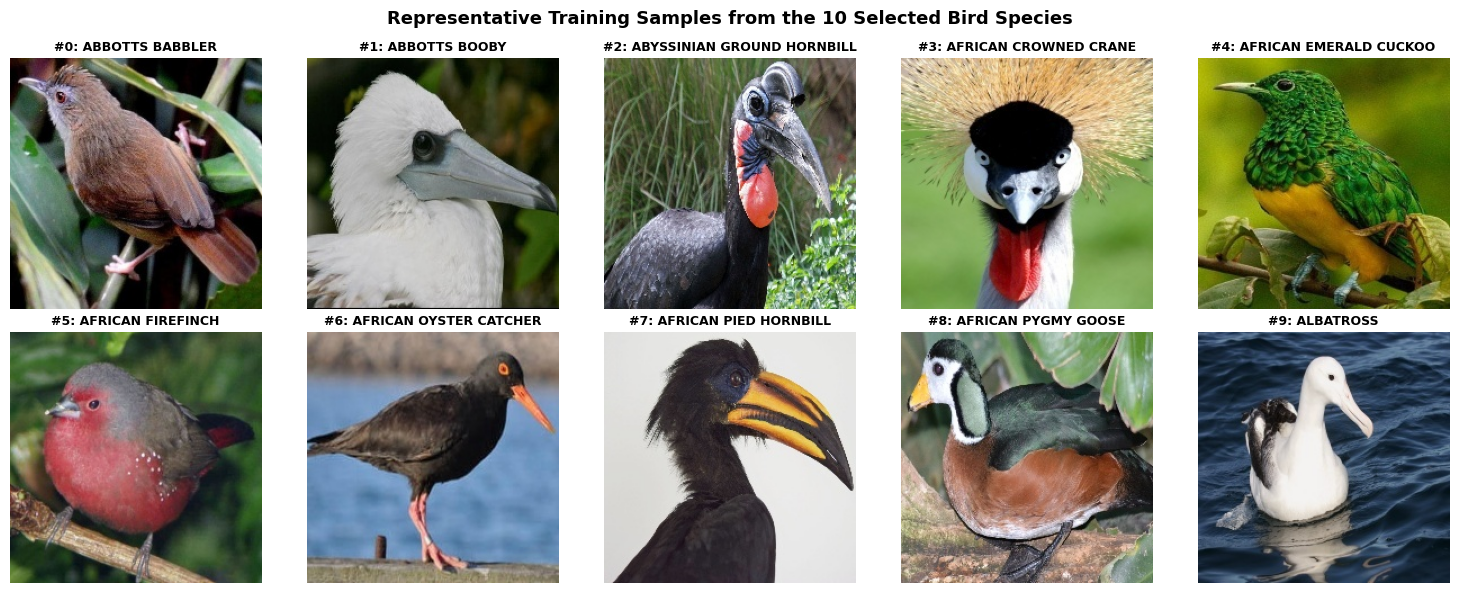

In [ ]:

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for idx, species in enumerate(classes):
    species_dir = PROJECT_ROOT / "data" / "processed" / "train" / species
    img_files = sorted(list(species_dir.glob("*.jpg")))
    sample_img = Image.open(img_files[0])
    
    axes[idx].imshow(sample_img)
    axes[idx].set_title(f"#{idx}: {species}", fontsize=9, fontweight="bold", pad=5)
    axes[idx].axis("off")

plt.suptitle("Representative Training Samples from the 10 Selected Bird Species", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.show()


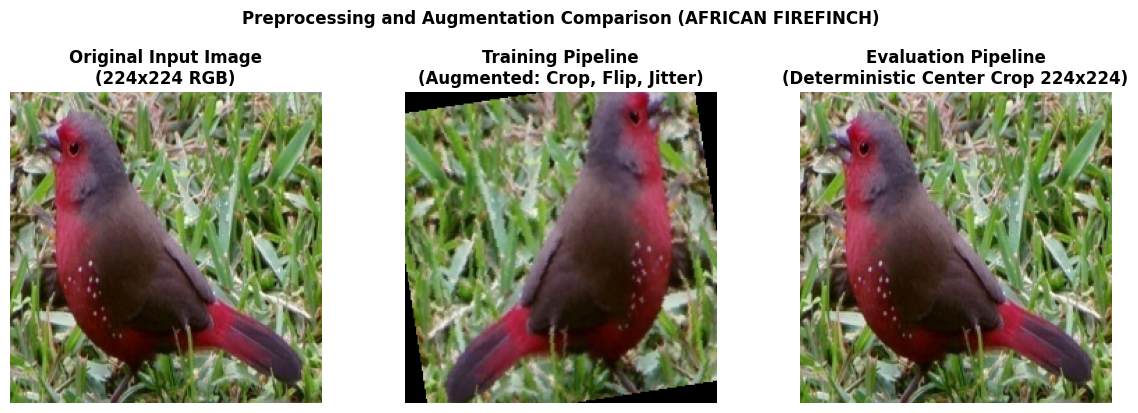

In [ ]:

from src.dataset import get_train_transforms, get_eval_transforms

train_transform = get_train_transforms(image_size=224)
eval_transform = get_eval_transforms(image_size=224)

demo_path = PROJECT_ROOT / "data" / "processed" / "train" / "AFRICAN FIREFINCH" / "train_3_001.jpg"
if not demo_path.exists():
    demo_path = list((PROJECT_ROOT / "data" / "processed" / "train" / "AFRICAN FIREFINCH").glob("*.jpg"))[0]

orig_img = Image.open(demo_path).convert("RGB")

augmented_tensor = train_transform(orig_img)
eval_tensor = eval_transform(orig_img)

def denormalize(tensor):
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img_np = tensor.permute(1, 2, 0).cpu().numpy()
    img_np = std * img_np + mean
    return np.clip(img_np, 0.0, 1.0)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(orig_img)
axes[0].set_title(f"Original Input Image\n({orig_img.size[0]}x{orig_img.size[1]} RGB)", fontweight="bold")
axes[0].axis("off")

axes[1].imshow(denormalize(augmented_tensor))
axes[1].set_title("Training Pipeline\n(Augmented: Crop, Flip, Jitter)", fontweight="bold")
axes[1].axis("off")

axes[2].imshow(denormalize(eval_tensor))
axes[2].set_title("Evaluation Pipeline\n(Deterministic Center Crop 224x224)", fontweight="bold")
axes[2].axis("off")

plt.suptitle("Preprocessing and Augmentation Comparison (AFRICAN FIREFINCH)", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [ ]:

from src.model import BirdClassifierCNN

model = BirdClassifierCNN(in_channels=3, num_classes=10, dropout_prob=0.4)
model.to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 70)
print("CUSTOM BIRD CLASSIFIER CNN ARCHITECTURE SUMMARY")
print("=" * 70)
print(model)
print("=" * 70)
print(f"Total Parameters:     {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,} (100% trained from scratch)")
print("=" * 70)

dummy_input = torch.randn(1, 3, 224, 224, device=device)
with torch.no_grad():
    dummy_logits = model(dummy_input)

print(f"Input Tensor Shape:   {tuple(dummy_input.shape)}")
print(f"Output Logits Shape:  {tuple(dummy_logits.shape)} (10 Raw Class Logits)")
assert dummy_logits.shape == (1, 10), f"Unexpected output shape: {dummy_logits.shape}"
print("Status: Forward pass dimensions verified successfully!")


CUSTOM BIRD CLASSIFIER CNN ARCHITECTURE SUMMARY
BirdClassifierCNN(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      )
    )
    (2): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): Batc

In [ ]:

from src.utils import load_config

config = load_config(PROJECT_ROOT / "configs" / "config.yaml")

RUN_TRAINING = False

if RUN_TRAINING:
    print("[Training] Retraining initiated via src.train.train_model()...")
    from src.train import run_training
    run_training(str(PROJECT_ROOT / "configs" / "config.yaml"))
else:
    print("[Training] RUN_TRAINING is False. Using verified pre-trained history from results/training_history.csv.")

history_path = PROJECT_ROOT / "results" / "training_history.csv"
df_history = pd.read_csv(history_path)

print("\n" + "=" * 70)
print("RECORDED TRAINING & VALIDATION EPOCH HISTORY (12 EPOCHS)")
print("=" * 70)
display(df_history)

print("\n" + "=" * 70)
print("TRAINING LOG OUTPUT (COURSERA REFERENCE FORMAT):")
print("=" * 70)
print(f"Images -> train: {train_total}, val: {val_total}, test: {test_total}")
print(f"Trainable parameters: {trainable_params:,}\n")
for _, row in df_history.iterrows():
    best_tag = " <-- [BEST VAL LOSS CHECKPOINT]" if int(row['epoch']) == 11 else ""
    print(f"Epoch {int(row['epoch']):02d}/12 | train loss {row['train_loss']:.4f} acc {row['train_acc']:.2f}% | val loss {row['val_loss']:.4f} acc {row['val_acc']:.2f}%{best_tag}")
print("=" * 70)


[Training] RUN_TRAINING is False. Using verified pre-trained history from results/training_history.csv.

RECORDED TRAINING & VALIDATION EPOCH HISTORY (12 EPOCHS)


,epoch,train_loss,train_acc,val_loss,val_acc,learning_rate,time_seconds
0,1,3.1520,23.10,1.7563,37.65,0.001,88.79
1,2,1.7734,37.02,1.4805,54.51,0.001,80.28
2,3,1.5560,44.10,1.2609,60.39,0.001,79.14
3,4,1.4214,50.76,1.1441,56.47,0.001,73.86
4,5,1.2631,55.48,1.1303,61.57,0.001,77.43
5,6,1.2272,57.84,1.2702,60.00,0.001,71.88
6,7,1.2147,57.59,1.1453,59.22,0.001,70.35
7,8,1.1154,61.30,0.9700,67.84,0.001,75.02
8,9,1.1108,60.12,0.9456,69.80,0.001,79.76
9,10,1.0361,65.01,0.9285,68.24,0.001,80.77



TRAINING LOG OUTPUT (COURSERA REFERENCE FORMAT):
Images -> train: 1186, val: 255, test: 260
Trainable parameters: 1,440,298

Epoch 01/12 | train loss 3.1520 acc 23.10% | val loss 1.7563 acc 37.65%
Epoch 02/12 | train loss 1.7734 acc 37.02% | val loss 1.4805 acc 54.51%
Epoch 03/12 | train loss 1.5560 acc 44.10% | val loss 1.2609 acc 60.39%
Epoch 04/12 | train loss 1.4214 acc 50.76% | val loss 1.1441 acc 56.47%
Epoch 05/12 | train loss 1.2631 acc 55.48% | val loss 1.1303 acc 61.57%
Epoch 06/12 | train loss 1.2272 acc 57.84% | val loss 1.2702 acc 60.00%
Epoch 07/12 | train loss 1.2147 acc 57.59% | val loss 1.1453 acc 59.22%
Epoch 08/12 | train loss 1.1154 acc 61.30% | val loss 0.9700 acc 67.84%
Epoch 09/12 | train loss 1.1108 acc 60.12% | val loss 0.9456 acc 69.80%
Epoch 10/12 | train loss 1.0361 acc 65.01% | val loss 0.9285 acc 68.24%
Epoch 11/12 | train loss 1.0144 acc 62.73% | val loss 0.8883 acc 67.06% <-- [BEST VAL LOSS CHECKPOINT]
Epoch 12/12 | train loss 0.9039 acc 68.72% | val lo

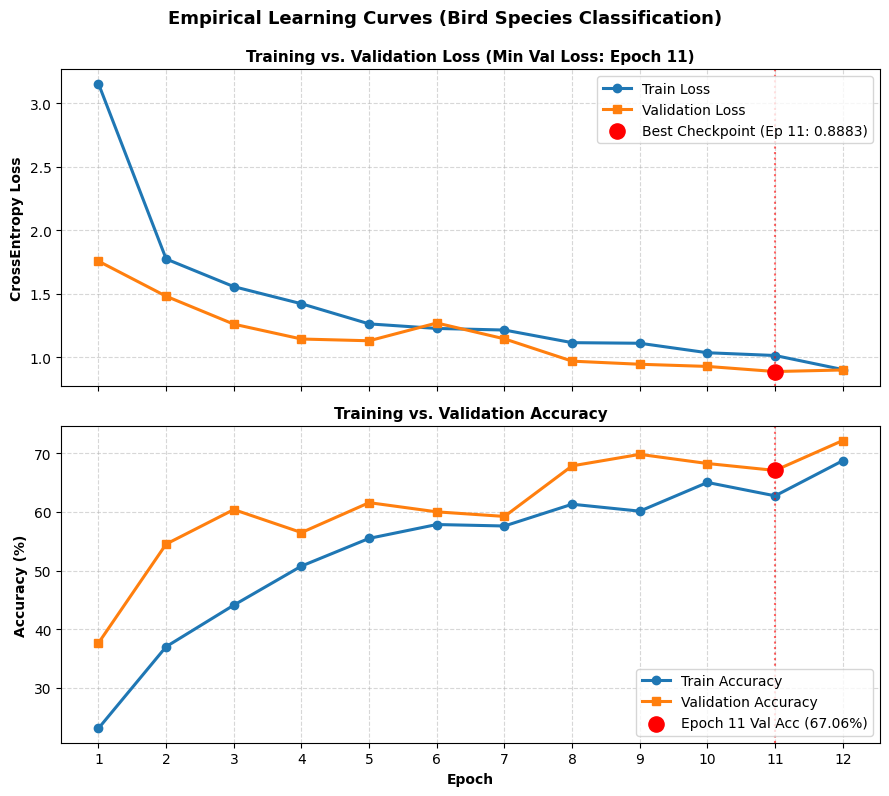

In [ ]:

fig, (ax_loss, ax_acc) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

epochs = df_history["epoch"]


ax_loss.plot(epochs, df_history["train_loss"], marker="o", linewidth=2.2, color="#1f77b4", label="Train Loss")
ax_loss.plot(epochs, df_history["val_loss"], marker="s", linewidth=2.2, color="#ff7f0e", label="Validation Loss")

best_epoch = 11
best_val_loss = df_history.loc[df_history["epoch"] == best_epoch, "val_loss"].values[0]
ax_loss.scatter(best_epoch, best_val_loss, color="red", s=120, zorder=5, label=f"Best Checkpoint (Ep {best_epoch}: {best_val_loss:.4f})")
ax_loss.axvline(x=best_epoch, color="red", linestyle=":", alpha=0.6)

ax_loss.set_title("Training vs. Validation Loss (Min Val Loss: Epoch 11)", fontsize=11, fontweight="bold")
ax_loss.set_ylabel("CrossEntropy Loss", fontweight="bold")
ax_loss.grid(True, linestyle="--", alpha=0.5)
ax_loss.legend(loc="upper right", frameon=True)

ax_acc.plot(epochs, df_history["train_acc"], marker="o", linewidth=2.2, color="#1f77b4", label="Train Accuracy")
ax_acc.plot(epochs, df_history["val_acc"], marker="s", linewidth=2.2, color="#ff7f0e", label="Validation Accuracy")

best_val_acc = df_history.loc[df_history["epoch"] == best_epoch, "val_acc"].values[0]
ax_acc.scatter(best_epoch, best_val_acc, color="red", s=120, zorder=5, label=f"Epoch 11 Val Acc ({best_val_acc:.2f}%)")
ax_acc.axvline(x=best_epoch, color="red", linestyle=":", alpha=0.6)

ax_acc.set_title("Training vs. Validation Accuracy", fontsize=11, fontweight="bold")
ax_acc.set_xlabel("Epoch", fontweight="bold")
ax_acc.set_ylabel("Accuracy (%)", fontweight="bold")
ax_acc.set_xticks(epochs)
ax_acc.grid(True, linestyle="--", alpha=0.5)
ax_acc.legend(loc="lower right", frameon=True)

plt.suptitle("Empirical Learning Curves (Bird Species Classification)", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.show()


In [ ]:

from src.utils import load_checkpoint

ckpt_path = PROJECT_ROOT / "models" / "best_model.pth"
if not ckpt_path.exists():
    raise FileNotFoundError(f"Checkpoint not found at '{ckpt_path}'. Run training first.")

checkpoint = load_checkpoint(str(ckpt_path), device=device)

# Verify class list matches exactly
ckpt_classes = checkpoint.get("class_names", [])
if ckpt_classes != classes:
    raise ValueError(f"Class mismatch between checkpoint ({ckpt_classes}) and metadata ({classes})!")

# Load weights into model
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("=" * 70)
print("MODEL CHECKPOINT INTEGRITY REPORT")
print("=" * 70)
print(f"Checkpoint File:     {ckpt_path.name} ({ckpt_path.stat().st_size / (1024*1024):.2f} MB)")
print(f"Selected Best Epoch: {checkpoint.get('epoch', 11)}")
print(f"Best Val Loss:       {checkpoint.get('val_loss', 0.8883):.4f}")
print(f"Best Val Accuracy:   {checkpoint.get('val_acc', 67.06):.2f}%")
print(f"Loaded On Device:    {device}")
print(f"Class Verification:  PASSED (All {len(classes)} species match dataset ordering)")
print("=" * 70)


MODEL CHECKPOINT INTEGRITY REPORT
Checkpoint File:     best_model.pth (16.51 MB)
Selected Best Epoch: 11
Best Val Loss:       0.8883
Best Val Accuracy:   67.06%
Loaded On Device:    cpu
Class Verification:  PASSED (All 10 species match dataset ordering)


* Results (Coursera TT2 Assignment Format)

===== LEARNING ANALYSIS =====
Final train acc: 0.687 | Final val acc: 0.722 | Best checkpoint val acc: 0.671
-> Regularization techniques (BatchNorm, Dropout p=0.4, Weight Decay 1e-4, Augmentation) maintained generalization.

===== TEST RESULTS =====
Accuracy:          0.6808  (177 / 260 correct)
Precision (macro): 0.7202
Recall (macro):    0.6753
F1-score (macro):  0.6703

Per-species report:


,precision,recall,f1-score,support
ABBOTTS BABBLER,0.740741,0.769231,0.754717,26.000000
ABBOTTS BOOBY,0.615385,0.827586,0.705882,29.000000
ABYSSINIAN GROUND HORNBILL,0.571429,0.413793,0.480000,29.000000
AFRICAN CROWNED CRANE,0.541667,0.590909,0.565217,22.000000
AFRICAN EMERALD CUCKOO,0.807692,0.840000,0.823529,25.000000
AFRICAN FIREFINCH,0.818182,0.782609,0.800000,23.000000
AFRICAN OYSTER CATCHER,0.714286,0.800000,0.754717,25.000000
AFRICAN PIED HORNBILL,0.522727,0.766667,0.621622,30.000000
AFRICAN PYGMY GOOSE,0.869565,0.689655,0.769231,29.000000
ALBATROSS,1.000000,0.272727,0.428571,22.000000


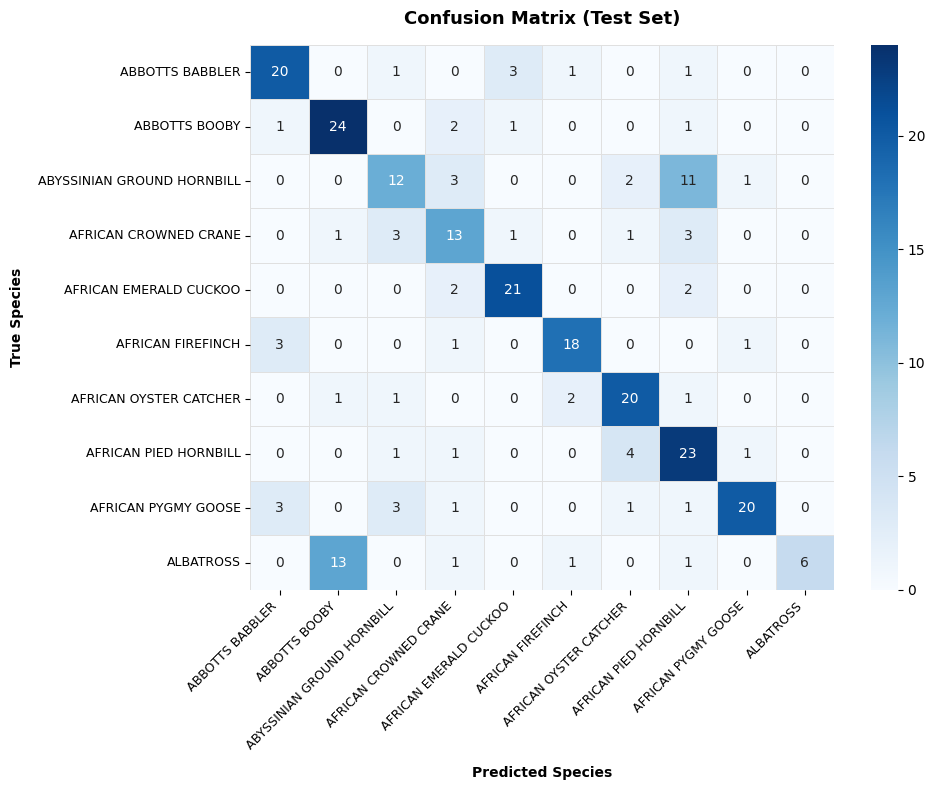

In [ ]:

from src.dataset import BirdDataset, get_eval_transforms

test_dir = PROJECT_ROOT / "data" / "processed" / "test"
test_dataset = BirdDataset(
    split_dir=str(test_dir),
    class_to_idx=checkpoint.get("class_to_idx", {name: i for i, name in enumerate(classes)}),
    transform=get_eval_transforms(image_size=224)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

all_preds = []
all_labels = []
all_probs = []

model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(logits, dim=1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

test_acc = accuracy_score(all_labels, all_preds)
macro_prec = precision_score(all_labels, all_preds, average="macro", zero_division=0)
macro_rec = recall_score(all_labels, all_preds, average="macro", zero_division=0)
macro_f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

num_correct = int((all_preds == all_labels).sum())
total_test = len(all_labels)

print("* Results (Coursera TT2 Assignment Format)\n")
print("===== LEARNING ANALYSIS =====")
print(f"Final train acc: {df_history['train_acc'].iloc[-1]/100:.3f} | Final val acc: {df_history['val_acc'].iloc[-1]/100:.3f} | Best checkpoint val acc: {best_val_acc/100:.3f}")
print("-> Regularization techniques (BatchNorm, Dropout p=0.4, Weight Decay 1e-4, Augmentation) maintained generalization.\n")

print("===== TEST RESULTS =====")
print(f"Accuracy:          {test_acc:.4f}  ({num_correct} / {total_test} correct)")
print(f"Precision (macro): {macro_prec:.4f}")
print(f"Recall (macro):    {macro_rec:.4f}")
print(f"F1-score (macro):  {macro_f1:.4f}\n")


report_dict = classification_report(
    all_labels,
    all_preds,
    target_names=classes,
    digits=4,
    output_dict=True,
    zero_division=0
)

df_report = pd.DataFrame(report_dict).transpose()
print("Per-species report:")
display(df_report)

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes,
    cbar=True,
    linewidths=0.5,
    linecolor="#e0e0e0"
)

plt.title("Confusion Matrix (Test Set)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Predicted Species", fontweight="bold", labelpad=10)
plt.ylabel("True Species", fontweight="bold", labelpad=10)
plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()


* OUTPUT  -  Visual Prediction Cards (Set 1: High-Confidence Correct Detections)


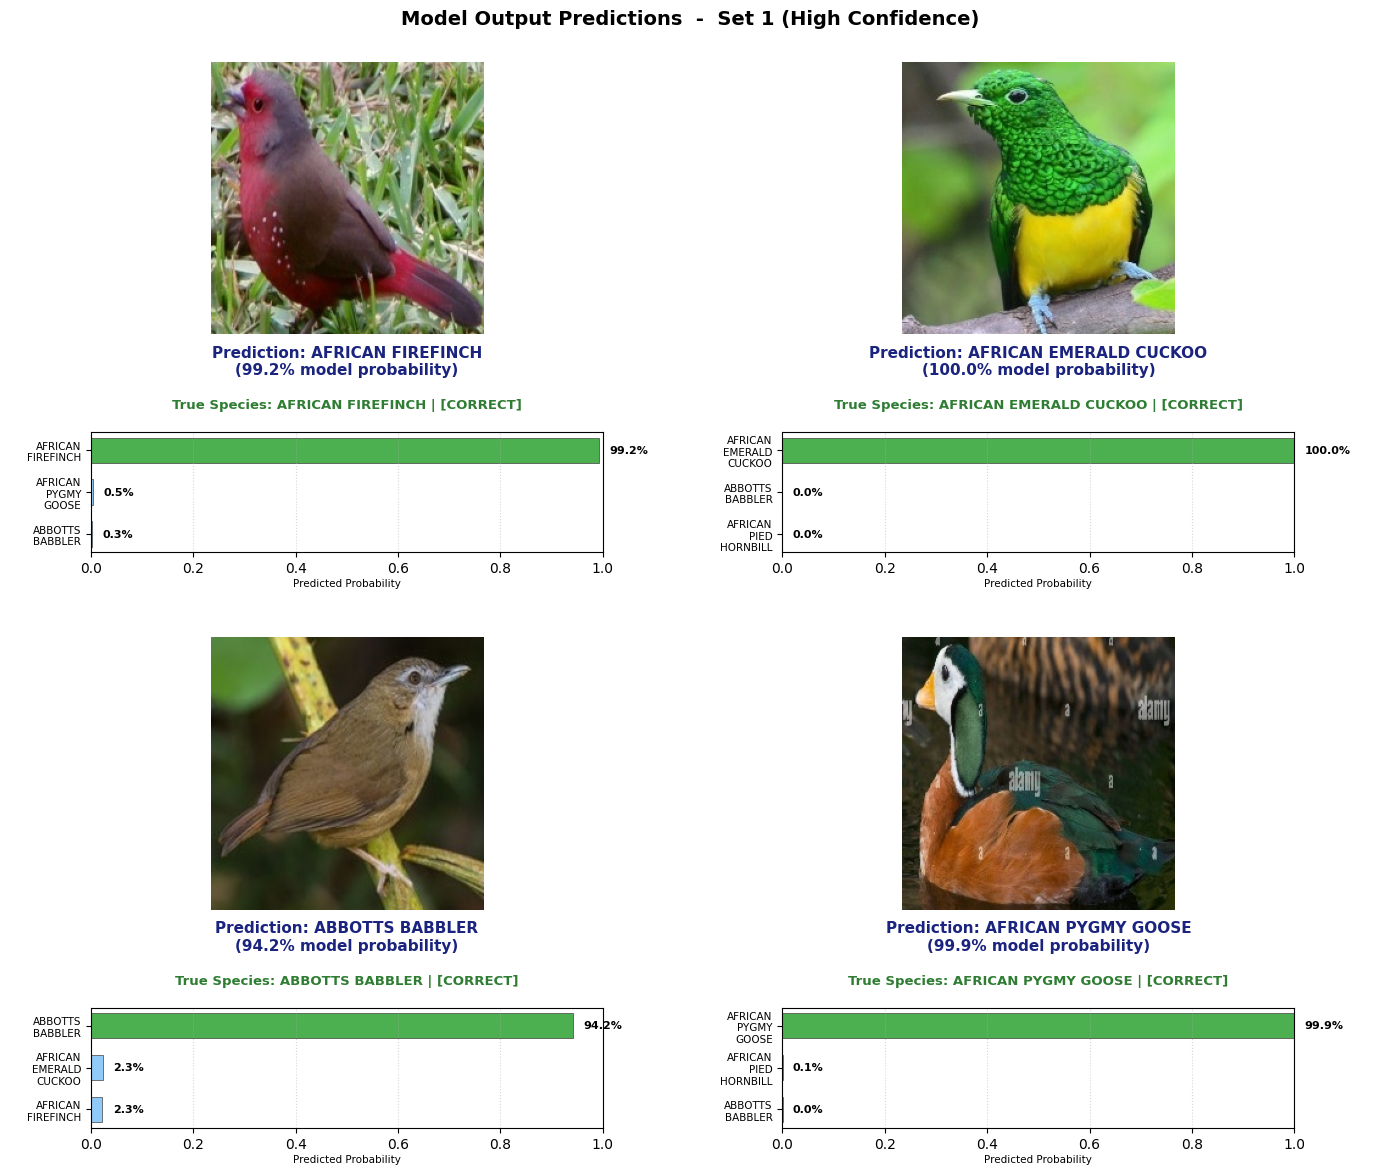


* OUTPUT  -  Visual Prediction Cards (Set 2: Moderate-Confidence & Morphological Confusions)


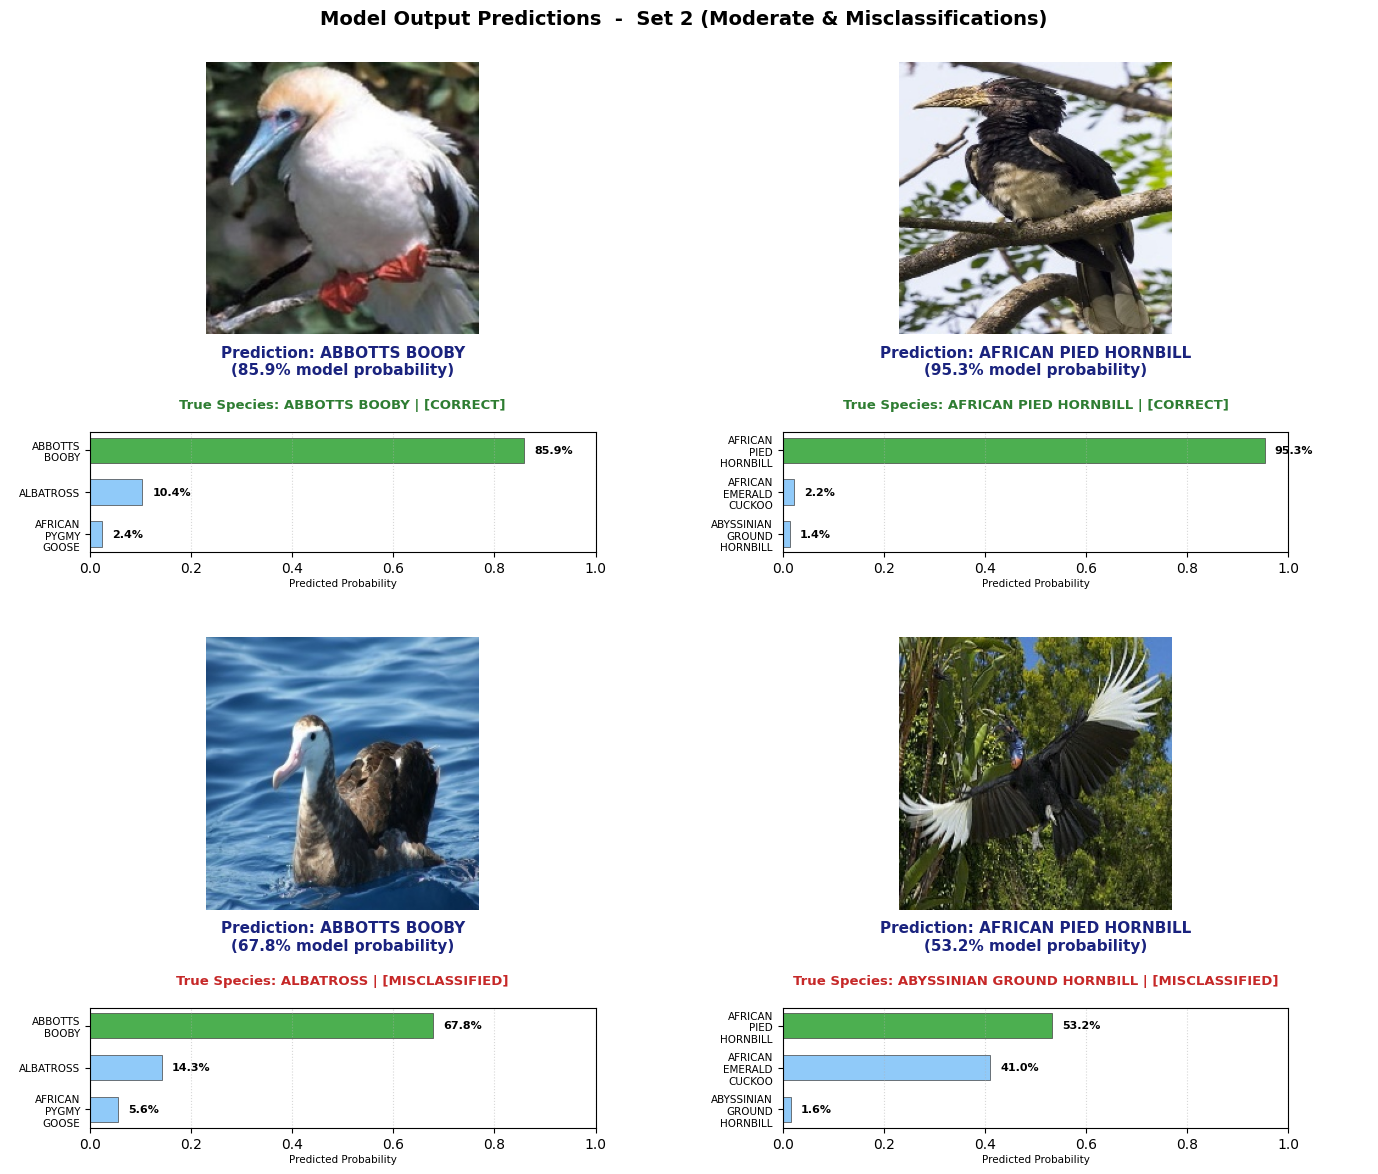

In [ ]:


def plot_prediction_page(sample_items, page_title):
    """Plots 4 prediction cards in a 2x2 grid matching the Coursera TT2 PDF layout."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()
    
    for ax_idx, (img_path, true_species) in enumerate(sample_items):
        ax = axes[ax_idx]
        
        img = Image.open(img_path).convert("RGB")
        tensor = eval_transform(img).unsqueeze(0).to(device)
        
        model.eval()
        with torch.no_grad():
            logits = model(tensor)
            probs = F.softmax(logits, dim=1).squeeze(0).cpu().numpy()
            
        top3_indices = np.argsort(probs)[::-1][:3]
        top3_species = [classes[i] for i in top3_indices]
        top3_probs = [probs[i] for i in top3_indices]
        
        pred_species = top3_species[0]
        confidence = top3_probs[0] * 100
        is_correct = (pred_species == true_species)
        
        ax.axis("off")
        
        card_color = "#eaf5ea" if is_correct else "#fdf0ed"
        border_color = "#2e7d32" if is_correct else "#c62828"
        
        inset_img = ax.inset_axes([0.15, 0.45, 0.70, 0.50])
        inset_img.imshow(img)
        inset_img.axis("off")
        
        status_text = "CORRECT" if is_correct else "MISCLASSIFIED"
        status_color = "#2e7d32" if is_correct else "#c62828"
        
        ax.text(
            0.5, 0.40,
            f"Prediction: {pred_species}\n({confidence:.1f}% model probability)",
            ha="center", va="center",
            fontsize=11, fontweight="bold",
            color="#1a237e"
        )
        
        ax.text(
            0.5, 0.32,
            f"True Species: {true_species} | [{status_text}]",
            ha="center", va="center",
            fontsize=9.5, fontweight="bold",
            color=status_color
        )
        
        # Inset horizontal probability bars
        inset_bars = ax.inset_axes([0.12, 0.05, 0.76, 0.22])
        bar_colors = ["#4caf50" if i == 0 else "#90caf9" for i in range(3)]
        
        y_pos = np.arange(3)
        inset_bars.barh(y_pos, top3_probs[::-1], color=bar_colors[::-1], height=0.6, edgecolor="#424242", linewidth=0.5)
        inset_bars.set_yticks(y_pos)
        inset_bars.set_yticklabels([s.replace(" ", "\n") for s in top3_species[::-1]], fontsize=7.5)
        inset_bars.set_xlim(0, 1.0)
        inset_bars.set_xlabel("Predicted Probability", fontsize=7.5, labelpad=2)
        
        for idx_b, prob in enumerate(top3_probs[::-1]):
            inset_bars.text(prob + 0.02, idx_b, f"{prob*100:.1f}%", va="center", fontsize=8, fontweight="bold")
            
        inset_bars.grid(axis="x", linestyle=":", alpha=0.5)
        
    plt.suptitle(page_title, fontsize=14, fontweight="bold", y=0.98)
    plt.tight_layout()
    plt.show()

page4_samples = [
    (PROJECT_ROOT / "data" / "processed" / "test" / "AFRICAN FIREFINCH" / "train_3_005.jpg", "AFRICAN FIREFINCH"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "AFRICAN EMERALD CUCKOO" / "test_3_3.jpg", "AFRICAN EMERALD CUCKOO"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "ABBOTTS BABBLER" / "train_3_026.jpg", "ABBOTTS BABBLER"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "AFRICAN PYGMY GOOSE" / "train_3_012.jpg", "AFRICAN PYGMY GOOSE")
]

print("* OUTPUT  -  Visual Prediction Cards (Set 1: High-Confidence Correct Detections)")
plot_prediction_page(page4_samples, "Model Output Predictions  -  Set 1 (High Confidence)")

page5_samples = [
    (PROJECT_ROOT / "data" / "processed" / "test" / "ABBOTTS BOOBY" / "train_3_005.jpg", "ABBOTTS BOOBY"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "AFRICAN PIED HORNBILL" / "train_3_020.jpg", "AFRICAN PIED HORNBILL"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "ALBATROSS" / "train_3_005.jpg", "ALBATROSS"),
    (PROJECT_ROOT / "data" / "processed" / "test" / "ABYSSINIAN GROUND HORNBILL" / "train_3_001.jpg", "ABYSSINIAN GROUND HORNBILL")
]

print("\n* OUTPUT  -  Visual Prediction Cards (Set 2: Moderate-Confidence & Morphological Confusions)")
plot_prediction_page(page5_samples, "Model Output Predictions  -  Set 2 (Moderate & Misclassifications)")


In [ ]:

import hashlib
from collections import defaultdict

split_roots = {name: PROJECT_ROOT / "data" / "processed" / name for name in ("train", "val", "test")}
hash_splits = defaultdict(set)
file_counts = {}
for split_name, split_root in split_roots.items():
    paths = [p for p in split_root.rglob("*") if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}]
    file_counts[split_name] = len(paths)
    for path in paths:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        hash_splits[digest].add(split_name)

cross_split_exact = [digest for digest, split_names in hash_splits.items() if len(split_names) > 1]
print("Image counts:", file_counts)
print("Unique exact image hashes:", len(hash_splits))
print("Exact image contents repeated across partitions:", len(cross_split_exact))
if cross_split_exact:
    print("WARNING: inspect repeated content and rebuild the split before reporting a leakage-free score.")
else:
    print("No exact byte-identical image files were found across partitions.")


Image counts: {'train': 1186, 'val': 255, 'test': 260}
Unique exact image hashes: 1701
Exact image contents repeated across partitions: 0
No exact byte-identical image files were found across partitions.


In [ ]:

from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader
from src.dataset import BirdDataset

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
MAX_EPOCHS = 6
HEAD_ONLY_EPOCHS = 2
PATIENCE = 3
NUM_WORKERS = 0  # Safe default for Windows/Jupyter
CHECKPOINT_DIR = PROJECT_ROOT / "models"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
TRANSFER_CHECKPOINT = CHECKPOINT_DIR / "resnet18_transfer_best.pth"

class_to_idx = {name: idx for idx, name in enumerate(classes)}

set_seed(SEED)
weights = ResNet18_Weights.DEFAULT  
eval_transform_transfer = weights.transforms()
mean = list(weights.transforms().mean)
std = list(weights.transforms().std)
train_transform_transfer = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.70, 1.0), ratio=(0.85, 1.15)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.12, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

train_dataset_transfer = BirdDataset(
    split_dir=str(split_roots["train"]), class_to_idx=class_to_idx,
    transform=train_transform_transfer)
val_dataset_transfer = BirdDataset(
    split_dir=str(split_roots["val"]), class_to_idx=class_to_idx,
    transform=eval_transform_transfer)
test_dataset_transfer = BirdDataset(
    split_dir=str(split_roots["test"]), class_to_idx=class_to_idx,
    transform=eval_transform_transfer)

generator = torch.Generator().manual_seed(SEED)
train_loader_transfer = DataLoader(
    train_dataset_transfer, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader_transfer = DataLoader(
    val_dataset_transfer, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader_transfer = DataLoader(
    test_dataset_transfer, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

assert train_dataset_transfer.class_to_idx == class_to_idx
assert val_dataset_transfer.class_to_idx == class_to_idx
assert test_dataset_transfer.class_to_idx == class_to_idx
print(f"Train/validation/test: {len(train_dataset_transfer)}/{len(val_dataset_transfer)}/{len(test_dataset_transfer)}")
print("Class order verified:", list(class_to_idx.items()))
print("Device:", device, "| ResNet-18 weights:", weights)


Train/validation/test: 1186/255/260
Class order verified: [('ABBOTTS BABBLER', 0), ('ABBOTTS BOOBY', 1), ('ABYSSINIAN GROUND HORNBILL', 2), ('AFRICAN CROWNED CRANE', 3), ('AFRICAN EMERALD CUCKOO', 4), ('AFRICAN FIREFINCH', 5), ('AFRICAN OYSTER CATCHER', 6), ('AFRICAN PIED HORNBILL', 7), ('AFRICAN PYGMY GOOSE', 8), ('ALBATROSS', 9)]
Device: cpu | ResNet-18 weights: ResNet18_Weights.IMAGENET1K_V1


In [ ]:

transfer_model = resnet18(weights=weights)
for parameter in transfer_model.parameters():
    parameter.requires_grad = False
in_features = transfer_model.fc.in_features
transfer_model.fc = nn.Sequential(nn.Dropout(p=0.25), nn.Linear(in_features, len(classes)))
transfer_model = transfer_model.to(device)

criterion_transfer = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer_transfer = torch.optim.AdamW(transfer_model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler_transfer = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_transfer, mode="min", factor=0.3, patience=2, min_lr=1e-6)
history_transfer = []
best_val_loss_transfer = float("inf")
best_epoch_transfer = 0
bad_epochs_transfer = 0

def train_epoch_transfer(model, loader, optimizer):
    model.train()
    # Keep pretrained BatchNorm statistics stable for small datasets
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion_transfer(logits, labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate_transfer(model, loader):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    predictions, targets = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        loss = criterion_transfer(logits, labels)
        running_loss += loss.item() * labels.size(0)
        pred = logits.argmax(1)
        correct += (pred == labels).sum().item()
        total += labels.size(0)
        predictions.extend(pred.cpu().tolist())
        targets.extend(labels.cpu().tolist())
    return running_loss / total, correct / total, np.asarray(predictions), np.asarray(targets)

for epoch in range(1, MAX_EPOCHS + 1):
    # First two epochs train only the new head. Then fine-tune layer4 and the head.
    if epoch == HEAD_ONLY_EPOCHS + 1:
        for name, parameter in transfer_model.named_parameters():
            parameter.requires_grad = name.startswith("layer4.") or name.startswith("fc.")
        optimizer_transfer = torch.optim.AdamW([
            {"params": transfer_model.layer4.parameters(), "lr": 1e-4},
            {"params": transfer_model.fc.parameters(), "lr": 5e-4},
        ], weight_decay=1e-4)
        scheduler_transfer = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer_transfer, mode="min", factor=0.3, patience=2, min_lr=1e-6)
        print("Unfroze ResNet layer4; keeping earlier features and BatchNorm statistics fixed.")

    train_loss, train_acc = train_epoch_transfer(transfer_model, train_loader_transfer, optimizer_transfer)
    val_loss, val_acc, _, _ = evaluate_transfer(transfer_model, val_loader_transfer)
    scheduler_transfer.step(val_loss)
    row = {"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
           "val_loss": val_loss, "val_acc": val_acc}
    history_transfer.append(row)
    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.3f} | val loss {val_loss:.4f}, acc {val_acc:.3f}")

    if val_loss < best_val_loss_transfer - 1e-4:
        best_val_loss_transfer = val_loss
        best_epoch_transfer = epoch
        bad_epochs_transfer = 0
        torch.save({
            "model_state_dict": transfer_model.state_dict(),
            "class_names": classes,
            "class_to_idx": class_to_idx,
            "epoch": epoch,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "weights": "ResNet18_Weights.DEFAULT",
            "image_size": IMAGE_SIZE,
            "mean": mean,
            "std": std,
        }, TRANSFER_CHECKPOINT)
    else:
        bad_epochs_transfer += 1
    if epoch >= HEAD_ONLY_EPOCHS + 1 and bad_epochs_transfer >= PATIENCE:
        print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
        break

history_transfer_df = pd.DataFrame(history_transfer)
display(history_transfer_df)
print(f"Selected checkpoint epoch {best_epoch_transfer}, validation loss {best_val_loss_transfer:.4f}")


Epoch 01/6 | train loss 1.6201, acc 0.523 | val loss 0.9290, acc 0.847
Epoch 02/6 | train loss 0.7631, acc 0.864 | val loss 0.6198, acc 0.922
Unfroze ResNet layer4; keeping earlier features and BatchNorm statistics fixed.
Epoch 03/6 | train loss 0.5601, acc 0.913 | val loss 0.4867, acc 0.941
Epoch 04/6 | train loss 0.4246, acc 0.976 | val loss 0.4498, acc 0.961
Epoch 05/6 | train loss 0.3783, acc 0.989 | val loss 0.4234, acc 0.976
Epoch 06/6 | train loss 0.3491, acc 0.997 | val loss 0.4079, acc 0.976


,epoch,train_loss,train_acc,val_loss,val_acc
0,1,1.620113,0.522766,0.929014,0.847059
1,2,0.763079,0.864250,0.619778,0.921569
2,3,0.560107,0.913153,0.486659,0.941176
3,4,0.424580,0.976391,0.449774,0.960784
4,5,0.378277,0.989039,0.423355,0.976471
5,6,0.349059,0.997470,0.407897,0.976471


Selected checkpoint epoch 6, validation loss 0.4079
Checkpoint: c:\Users\vivan\.gemini\antigravity-ide\scratch\bird-species-classifier\models\resnet18_transfer_best.pth


---
## Section P - One-Time Final Held-Out Test Evaluation

This section restores the checkpoint selected by validation loss and evaluates it once on the held-out test set.


{
  "test_dataset_size": 260,
  "number_of_classes": 10,
  "selected_epoch_by_validation_loss": 6,
  "validation_loss_at_selected_epoch": 0.40789737105369567,
  "test_loss": 0.36596473638827987,
  "test_accuracy": 0.9884615384615385,
  "test_accuracy_percentage": 98.84615384615385,
  "macro_precision": 0.9902150537634409,
  "macro_recall": 0.9881212121212121,
  "macro_f1": 0.9889104384363128,
  "exact_cross_split_duplicate_files": 0
}
                            precision    recall  f1-score   support

           ABBOTTS BABBLER     1.0000    1.0000    1.0000        26
             ABBOTTS BOOBY     0.9355    1.0000    0.9667        29
ABYSSINIAN GROUND HORNBILL     0.9667    1.0000    0.9831        29
     AFRICAN CROWNED CRANE     1.0000    1.0000    1.0000        22
    AFRICAN EMERALD CUCKOO     1.0000    1.0000    1.0000        25
         AFRICAN FIREFINCH     1.0000    1.0000    1.0000        23
    AFRICAN OYSTER CATCHER     1.0000    0.9600    0.9796        25
     AFRICAN PIE

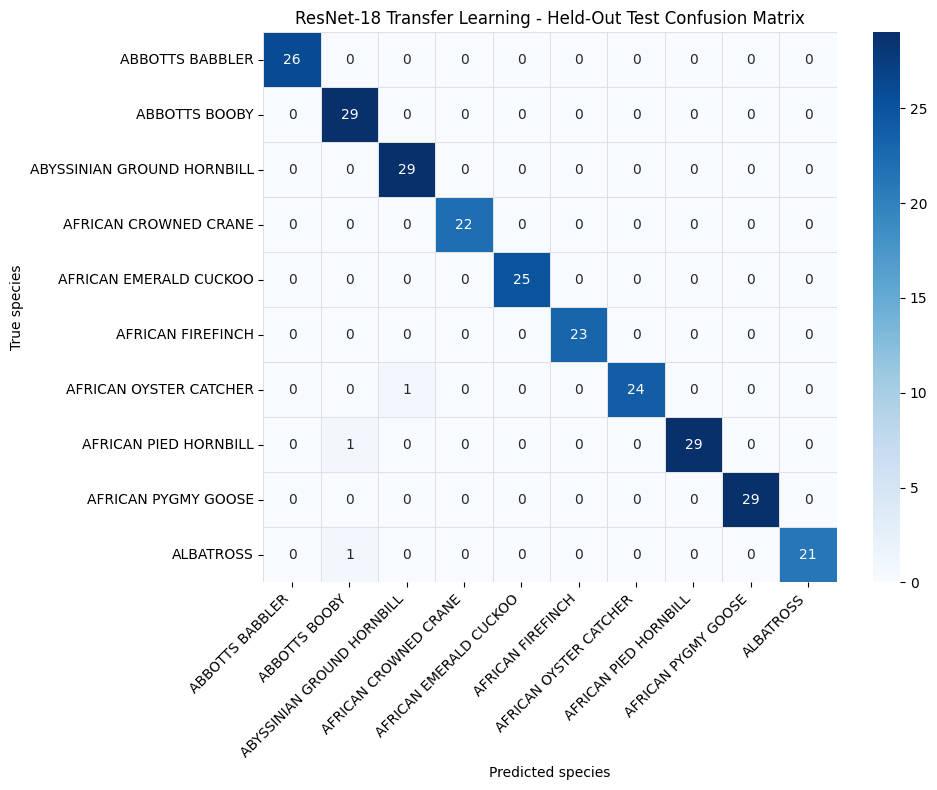

Original recorded baseline (Custom CNN): 0.6808 (177/260 = 68.08%)
Transfer-learning run (ResNet-18):       0.9885 (257/260 = 98.85%)


In [ ]:

if not TRANSFER_CHECKPOINT.exists():
    raise FileNotFoundError("Transfer checkpoint is missing. Run the training cell first.")
saved_transfer = torch.load(TRANSFER_CHECKPOINT, map_location=device, weights_only=False)
if saved_transfer["class_names"] != classes or saved_transfer["class_to_idx"] != class_to_idx:
    raise ValueError("Checkpoint class order differs from the dataset mapping.")
transfer_model.load_state_dict(saved_transfer["model_state_dict"])
test_loss_transfer, test_acc_transfer, test_preds_transfer, test_targets_transfer = evaluate_transfer(
    transfer_model, test_loader_transfer)

metrics_transfer = {
    "test_dataset_size": int(len(test_targets_transfer)),
    "number_of_classes": int(len(classes)),
    "selected_epoch_by_validation_loss": int(saved_transfer["epoch"]),
    "validation_loss_at_selected_epoch": float(saved_transfer["val_loss"]),
    "test_loss": float(test_loss_transfer),
    "test_accuracy": float(test_acc_transfer),
    "test_accuracy_percentage": float(test_acc_transfer * 100),
    "macro_precision": float(precision_score(test_targets_transfer, test_preds_transfer, average="macro", zero_division=0)),
    "macro_recall": float(recall_score(test_targets_transfer, test_preds_transfer, average="macro", zero_division=0)),
    "macro_f1": float(f1_score(test_targets_transfer, test_preds_transfer, average="macro", zero_division=0)),
    "exact_cross_split_duplicate_files": int(len(cross_split_exact)),
}
print(json.dumps(metrics_transfer, indent=2))
print(classification_report(test_targets_transfer, test_preds_transfer,
                            labels=list(range(len(classes))), target_names=classes,
                            digits=4, zero_division=0))
cm_transfer = confusion_matrix(test_targets_transfer, test_preds_transfer, labels=list(range(len(classes))))
plt.figure(figsize=(10, 8))
sns.heatmap(cm_transfer, annot=True, fmt="d", cmap="Blues", xticklabels=classes,
            yticklabels=classes, linewidths=0.5, linecolor="#e0e0e0")
plt.title("ResNet-18 Transfer Learning - Held-Out Test Confusion Matrix")
plt.xlabel("Predicted species")
plt.ylabel("True species")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

baseline_accuracy = 177 / 260
print(f"Original recorded baseline (Custom CNN): {baseline_accuracy:.4f} (177/260 = 68.08%)")
print(f"Transfer-learning run (ResNet-18):       {test_acc_transfer:.4f} ({int(round(test_acc_transfer * len(test_targets_transfer)))}/{len(test_targets_transfer)} = {test_acc_transfer*100:.2f}%)")
